# Y Combinator Startup Industry and Outcome Analysis

## Research Question

How do startup outcomes vary across different Y Combinator industries?

This analysis examines whether startups in certain industries have different
outcome distributions than others.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

Matplotlib is building the font cache; this may take a moment.


In [65]:
df = pd.read_csv('../data/yc_companies_2026-05-07.csv')
df.columns


Index(['id', 'name', 'slug', 'batch', 'batch_year', 'batch_season', 'era',
       'status', 'outcome', 'stage', 'top_company', 'team_size', 'team_bucket',
       'industry', 'subindustry', 'industries', 'tags', 'city', 'region',
       'country', 'regions', 'in_sf_bay', 'in_us', 'is_remote', 'company_age',
       'is_hiring', 'nonprofit', 'launched_date', 'website', 'one_liner',
       'long_description'],
      dtype='str')

In [8]:

conn = sqlite3.connect("../data/yc_startups.db")
df = pd.read_sql_query("SELECT * FROM yc_companies", conn)
df.head()

,id,name,slug,batch,batch_year,batch_season,era,status,outcome,stage,...,in_sf_bay,in_us,is_remote,company_age,is_hiring,nonprofit,launched_date,website,one_liner,long_description
0,26331,BBy,bby,Winter 2022,2022.0,Winter,2015-2024,Active,Surviving,Growth,...,0,1,0,4.0,0,0,2022-02-02,http://www.bbymilk.com,BBy powders breast milk that's immunologically...,BBy's condensing device turns milk into a fine...
1,26311,WhiteLab Genomics,whitelab-genomics,Winter 2022,2022.0,Winter,2015-2024,Active,Surviving,Growth,...,0,0,0,4.0,0,0,2022-02-11,https://whitelabgx.com,Unleashing the potential of DNA and RNA based ...,We have developed an AI platform enabling to a...
2,26307,Mindbase,tradex,Winter 2022,2022.0,Winter,2015-2024,Active,Surviving,Early,...,1,1,1,4.0,1,0,2022-01-21,https://mymindbase.ai,Build AI influencers that autonomously create ...,Mindbase is an AI avatar platform where we lau...
3,26303,Massdriver,massdriver,Winter 2022,2022.0,Winter,2015-2024,Active,Surviving,Early,...,0,1,1,4.0,0,0,2022-01-14,https://massdriver.cloud,"Deploy secure, scalable cloud infrastructure i...",Massdriver helps engineering and operations te...
4,26296,Reality Defender,reality-defender,Winter 2022,2022.0,Winter,2015-2024,Active,Surviving,Growth,...,0,1,0,4.0,1,0,2022-03-21,http://www.realitydefender.com,Enterprise Deepfake Detection,Reality Defender is the market leader in deepf...


In [18]:
query = """
SELECT
    industry,
    outcome,
    COUNT(*) AS company_count
FROM yc_companies
WHERE industry IS NOT NULL
  AND outcome IS NOT NULL
GROUP BY industry, outcome
ORDER BY industry, company_count DESC;
"""

industry_outcomes = pd.read_sql_query(query, conn)

industry_outcomes.head(5)

,industry,outcome,company_count
0,B2B,Surviving,2140
1,B2B,Failed,440
2,B2B,Successful,430
3,Consumer,Surviving,411
4,Consumer,Failed,308


In [13]:
pivot = industry_outcomes.pivot(
    index="industry",
    columns="outcome",
    values="company_count"
).fillna(0)

pivot

outcome,Failed,Successful,Surviving
industry,,,
B2B,440.0,430.0,2140.0
Consumer,308.0,152.0,411.0
Education,20.0,18.0,86.0
Fintech,82.0,80.0,461.0
Government,5.0,5.0,31.0
Healthcare,94.0,59.0,514.0
Industrials,51.0,31.0,293.0
Real Estate and Construction,32.0,26.0,97.0
Unspecified,1.0,0.0,17.0


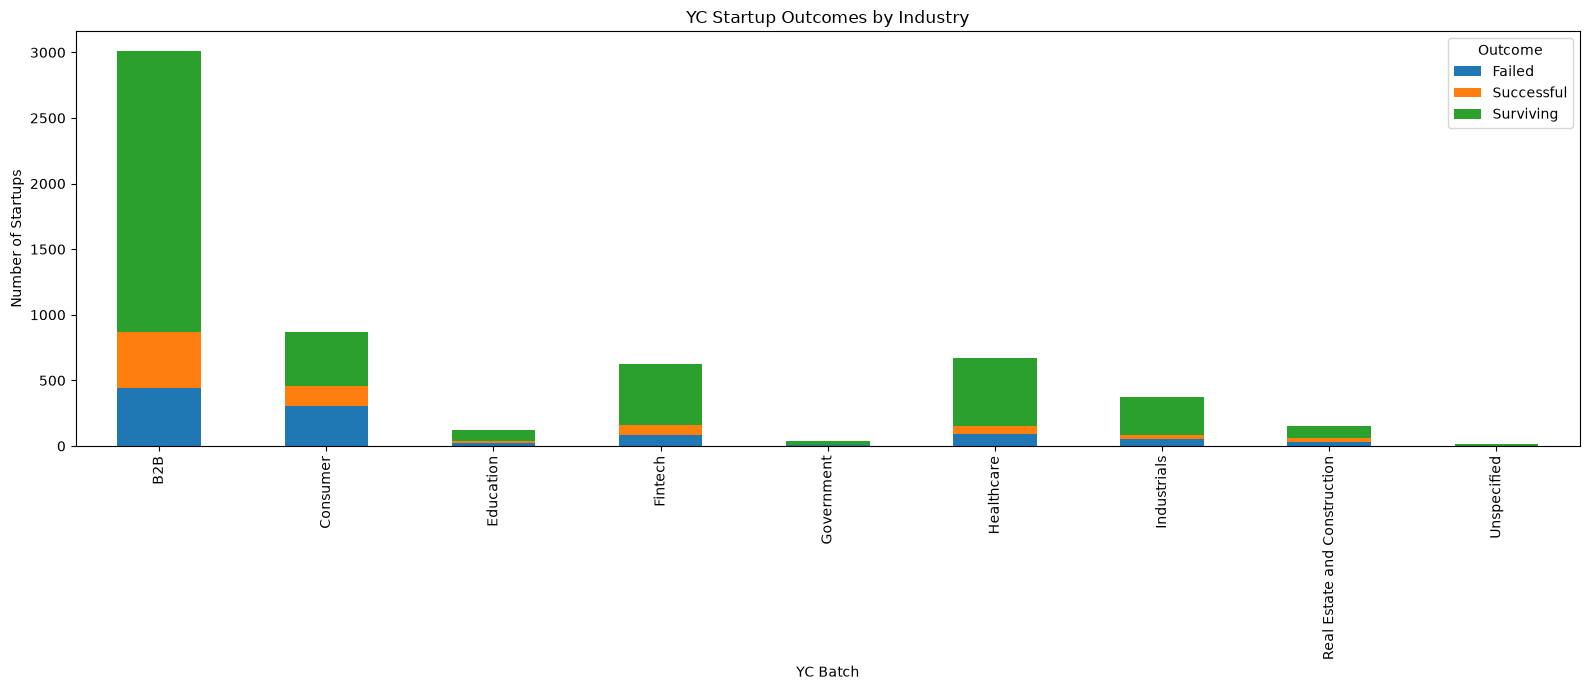

In [67]:
pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(16, 7)
)

plt.title("YC Startup Outcomes by Industry")
plt.xlabel("YC Batch")
plt.ylabel("Number of Startups")
plt.xticks(rotation=90)
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

In [14]:
percentages = pivot.div(pivot.sum(axis=1), axis=0) * 100

percentages

outcome,Failed,Successful,Surviving
industry,,,
B2B,14.617940,14.285714,71.096346
Consumer,35.361653,17.451206,47.187141
Education,16.129032,14.516129,69.354839
Fintech,13.162119,12.841091,73.996790
Government,12.195122,12.195122,75.609756
Healthcare,14.092954,8.845577,77.061469
Industrials,13.600000,8.266667,78.133333
Real Estate and Construction,20.645161,16.774194,62.580645
Unspecified,5.555556,0.000000,94.444444


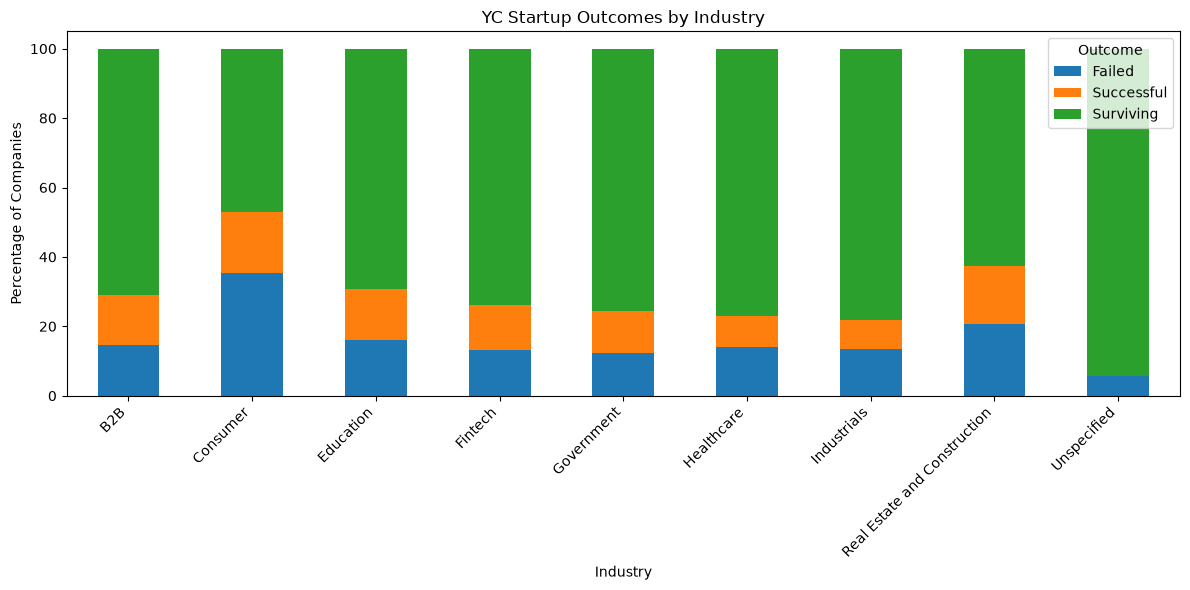

In [15]:
percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("YC Startup Outcomes by Industry")
plt.xlabel("Industry")
plt.ylabel("Percentage of Companies")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

In [26]:
print(df["outcome"].value_counts(dropna=False), '\n',
df["status"].value_counts(dropna=False))

outcome
Surviving     4050
Failed        1033
Successful     801
Name: count, dtype: int64 
 status
Active      4050
Inactive    1033
Acquired     778
Public        23
Name: count, dtype: int64


In [47]:
query = """
SELECT
    batch,
    batch_year,
    outcome,
    COUNT(*) AS company_count
FROM yc_companies
GROUP BY batch, outcome
ORDER BY batch;
"""

batch_outcomes = pd.read_sql_query(query, conn)

batch_outcomes.head()

,batch,batch_year,outcome,company_count
0,Fall 2024,2024.0,Failed,3
1,Fall 2024,2024.0,Successful,1
2,Fall 2024,2024.0,Surviving,89
3,Fall 2025,2025.0,Failed,2
4,Fall 2025,2025.0,Surviving,146


In [48]:
batch_outcomes["season"] = batch_outcomes["batch"].str.split().str[0]

In [ ]:
season_order = {
    "Winter": 1,
    "Summer": 2,
    "Fall": 3
}

batch_outcomes["season_num"] = (
    batch_outcomes["season"].map(season_order)
)

In [59]:
batch_outcomes = batch_outcomes.sort_values(
    ["batch_year", "season_num"]
)

batch_outcomes.head(20)

,batch,batch_year,outcome,company_count,season,season_num
10,Summer 2005,2005.0,Failed,3,Summer,2.0
11,Summer 2005,2005.0,Successful,6,Summer,2.0
74,Winter 2006,2006.0,Failed,3,Winter,1.0
75,Winter 2006,2006.0,Successful,4,Winter,1.0
12,Summer 2006,2006.0,Failed,8,Summer,2.0
13,Summer 2006,2006.0,Successful,2,Summer,2.0
14,Summer 2006,2006.0,Surviving,1,Summer,2.0
76,Winter 2007,2007.0,Failed,5,Winter,1.0
77,Winter 2007,2007.0,Successful,6,Winter,1.0
78,Winter 2007,2007.0,Surviving,2,Winter,1.0


In [61]:
batch_order = batch_outcomes["batch"].drop_duplicates()
batch_pivot = batch_outcomes.pivot(
    index="batch",
    columns="outcome",
    values="company_count"
).fillna(0)

batch_pivot = batch_pivot.reindex(batch_order)

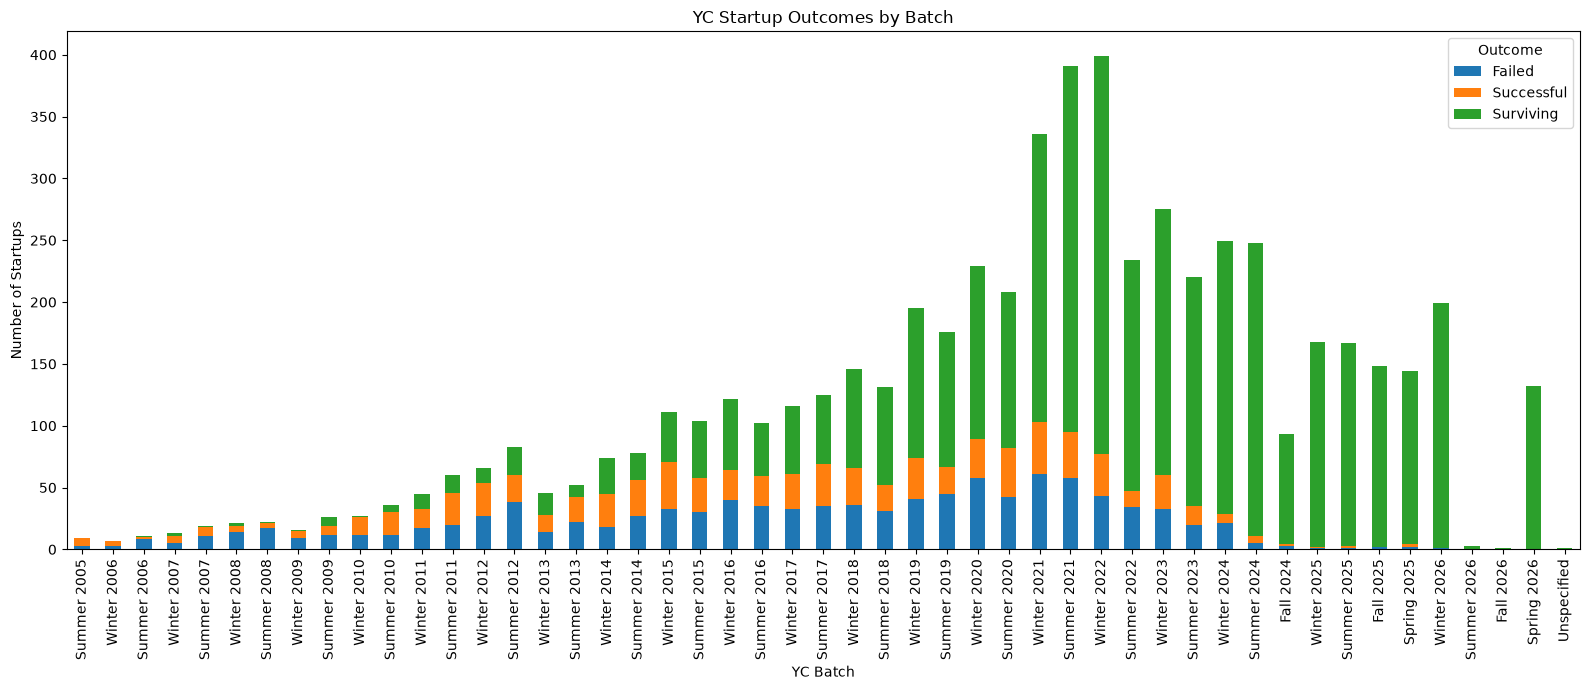

In [68]:
batch_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(16, 7)
)

plt.title("YC Startup Outcomes by Batch")
plt.xlabel("YC Batch")
plt.ylabel("Number of Startups")
plt.xticks(rotation=90)
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

In [69]:
batch_percentages = batch_pivot.div(
    batch_pivot.sum(axis=1),
    axis=0
) * 100

batch_percentages.head()

outcome,Failed,Successful,Surviving
batch,,,
Summer 2005,33.333333,66.666667,0.000000
Winter 2006,42.857143,57.142857,0.000000
Summer 2006,72.727273,18.181818,9.090909
Winter 2007,38.461538,46.153846,15.384615
Summer 2007,57.894737,36.842105,5.263158


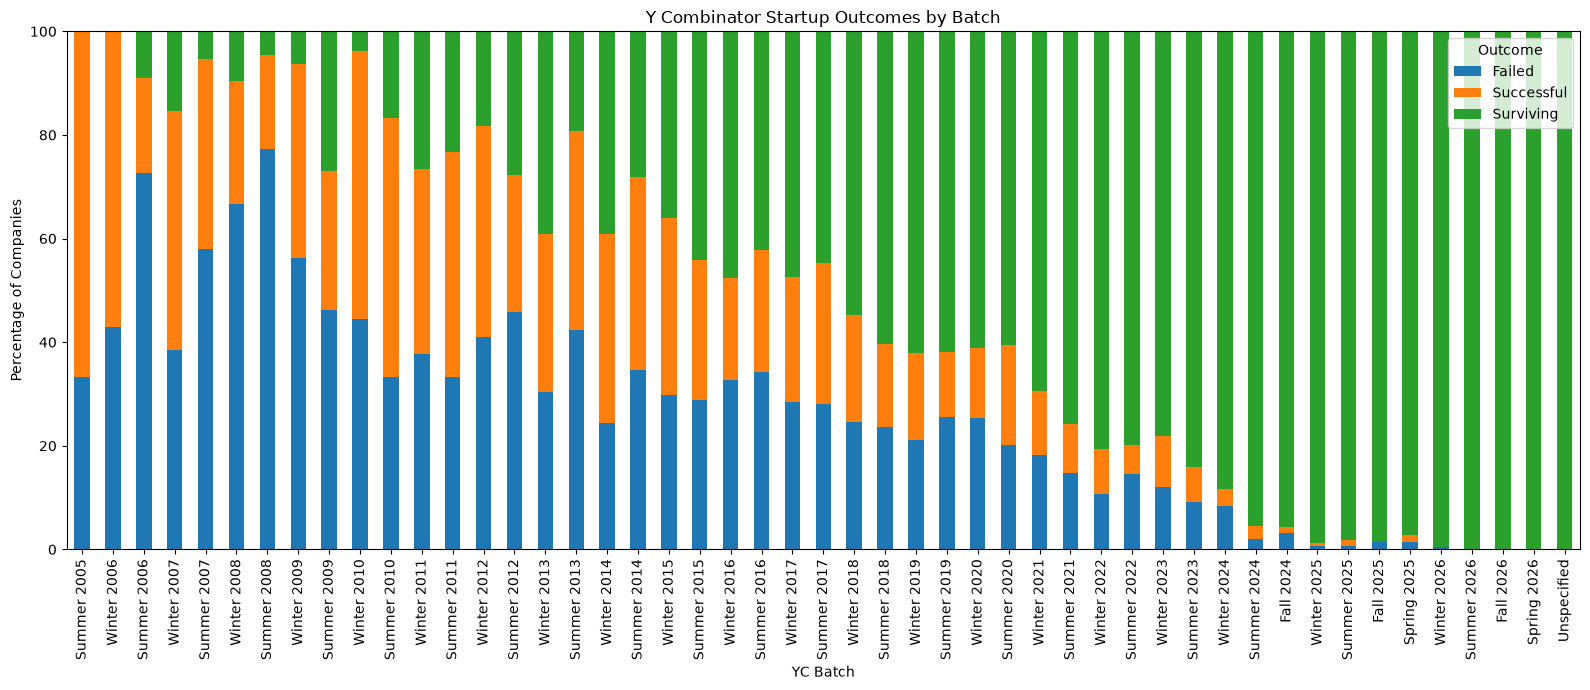

In [70]:
batch_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(16, 7)
)

plt.title("Y Combinator Startup Outcomes by Batch")
plt.xlabel("YC Batch")
plt.ylabel("Percentage of Companies")
plt.xticks(rotation=90)
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

Graph shows trend that the older the startup, the more likely it has been aquired/failed. No notable spikes.